In [2]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import csv

In [3]:
DATASET_DIR = './dataset/'
DATASET_FILE = './dataset/list.csv'

def read_csv(filename):
    data = dict()
    with open(filename, 'r') as f:
        reader = csv.reader(f)
        for row in reader:
            data[row[0]] = int(row[1])
    return data

def load_images_and_masks(image_classes):
    images = []
    masks = []
    ids = []
    labels = []
    for im_id, cls in image_classes.items():
        img = cv2.imread(f"{DATASET_DIR}/images/{im_id}.jpg")
        mask = cv2.imread(f"{DATASET_DIR}/masks/{im_id}_Segmentation.png", cv2.IMREAD_GRAYSCALE)
        
        if img is not None and mask is not None:
            images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            masks.append(mask)
            ids.append(im_id)
            labels.append(cls)
    return images, masks, ids, labels

# Load data
image_dict = read_csv(DATASET_FILE)
images, masks_gt, ids, labels = load_images_and_masks(image_dict)
print(f"Loaded {len(images)} images.")


Loaded 51 images.


PHASE 1: 

**1.1 Processing and Segmentation**

Execution of the segmentation pipeline on the images: preprocessing (hair removal), Otsu binarization, and morphological closing to obtain solid masks.

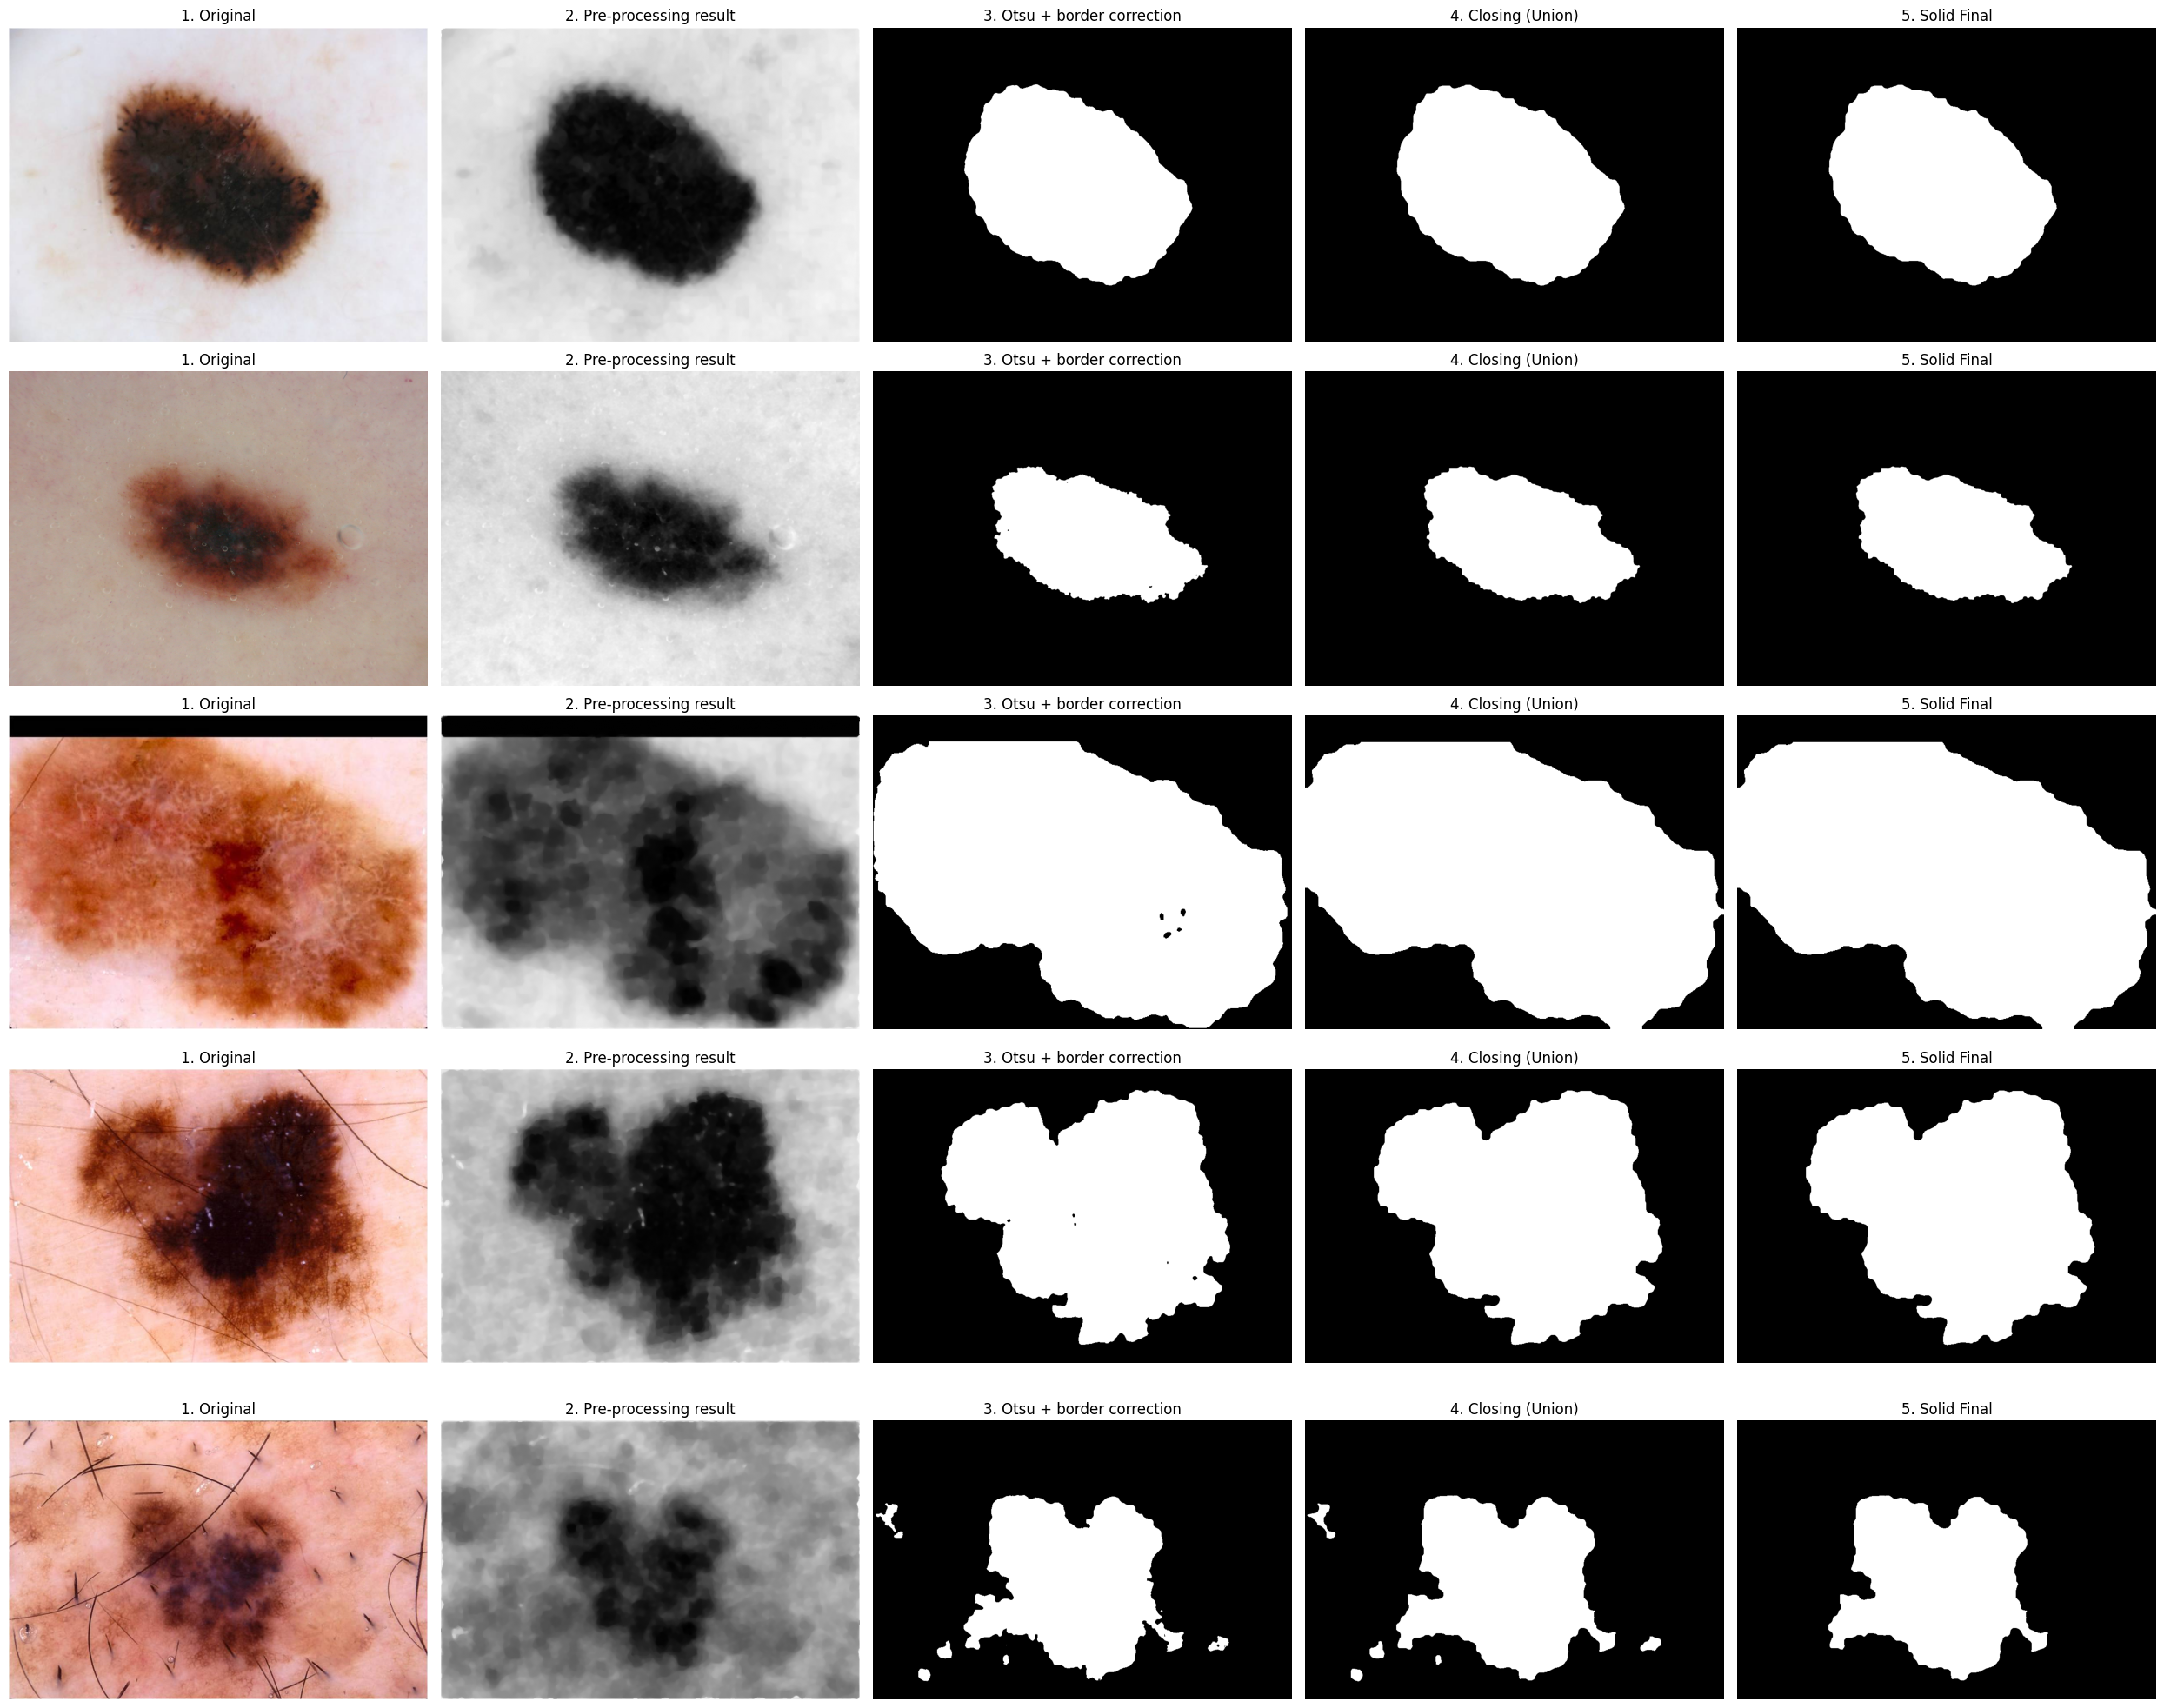

Segmentation completed. 51 masks ready.


In [4]:
mis_segmentaciones = []

# Kernels 
kernel_pelo = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
kernel_union = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (20, 20))

n_total = len(images)
fig, axes = plt.subplots(5, 5, figsize=(25, 20))


for i in range(n_total):
    img_rgb = images[i]
    blue = img_rgb[:,:,2].copy() 
    
    # --- 1. PRE-PROCESSING ---
    bh = cv2.morphologyEx(blue, cv2.MORPH_BLACKHAT, kernel_pelo)
    _, m_pelo = cv2.threshold(bh, 10, 255, cv2.THRESH_BINARY)
    blue_limpio = cv2.inpaint(blue, m_pelo, 1, cv2.INPAINT_TELEA)
    img_blur = cv2.medianBlur(blue_limpio, 9) 
    
    # --- 2. OTSU SEGMENTATION ---
    _, mask_raw = cv2.threshold(img_blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    
    # --- 3. MASK CLEANING (Remove borders) ---
    margen_v = 45
    
    # Calculate white density in top and bottom margins
    # np.mean returns a value between 0 and 255
    
    densidad_arriba = np.mean(mask_raw[:margen_v, :])
    
    # If density is high, there is a border artifact
    if densidad_arriba > 200:
        mask_raw[:margen_v, :] = 0
    densidad_abajo = np.mean(mask_raw[-margen_v:, :])
    if densidad_abajo > 200:
        mask_raw[-margen_v:, :] = 0
    
    # --- 4. REPAIR AND CLOSING ---
    mask_reparada = cv2.morphologyEx(mask_raw, cv2.MORPH_CLOSE, kernel_union)
    
    # --- 5. FINAL RESULT (Contours) ---
    cnts, _ = cv2.findContours(mask_reparada, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask_final = np.zeros_like(mask_reparada)
    if cnts:
        c_max = max(cnts, key=cv2.contourArea)
        cv2.drawContours(mask_final, [c_max], -1, 255, thickness=-1)
    
    mis_segmentaciones.append(mask_final)

    # --- VISUALIZATION ---

    if i < 5:
        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title("1. Original")
        
        axes[i, 1].imshow(img_blur, cmap='gray')
        axes[i, 1].set_title("2. Pre-processing result")
        
        axes[i, 2].imshow(mask_raw, cmap='gray')
        axes[i, 2].set_title("3. Otsu + border correction")
        
        axes[i, 3].imshow(mask_reparada, cmap='gray')
        axes[i, 3].set_title("4. Closing (Union)")
        
        axes[i, 4].imshow(mask_final, cmap='gray')
        axes[i, 4].set_title("5. Solid Final")
        
        for ax in axes[i]: ax.axis('off')

plt.tight_layout()
plt.show()

print(f"Segmentation completed. {len(mis_segmentaciones)} masks ready.")


**1.2 Segmentation Validation**

Calculation of the Jaccard index (IoU) and quantification of False Positives (FP) and False Negatives (FN) by comparing the obtained masks against the *Ground Truth*.

--- IMAGEN ID: ISIC_0000013 ---
IoU: 0.9619 (96.19%) | FP: 149 px | FN: 7193 px


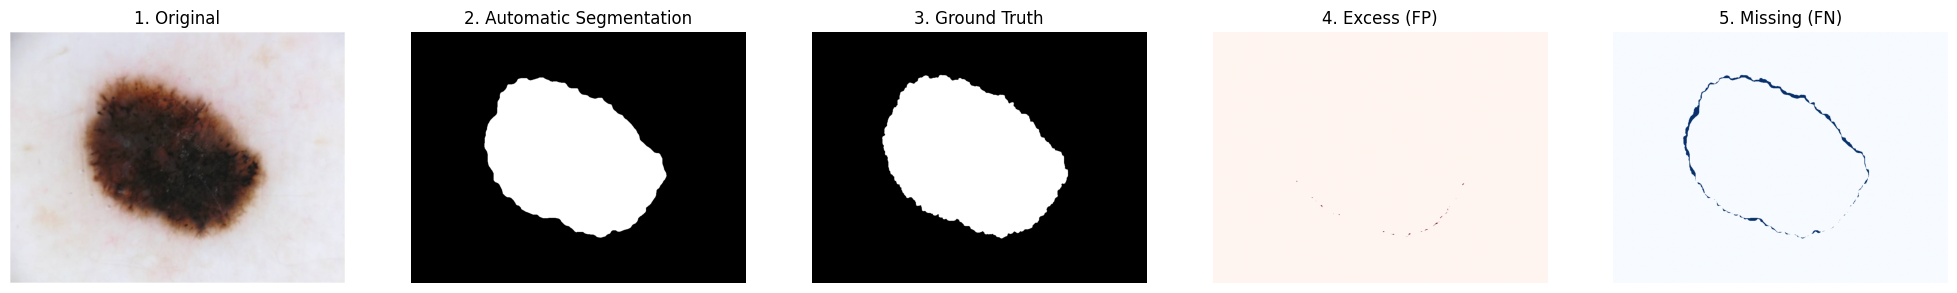

--- IMAGEN ID: ISIC_0000141 ---
IoU: 0.8634 (86.34%) | FP: 56 px | FN: 73736 px


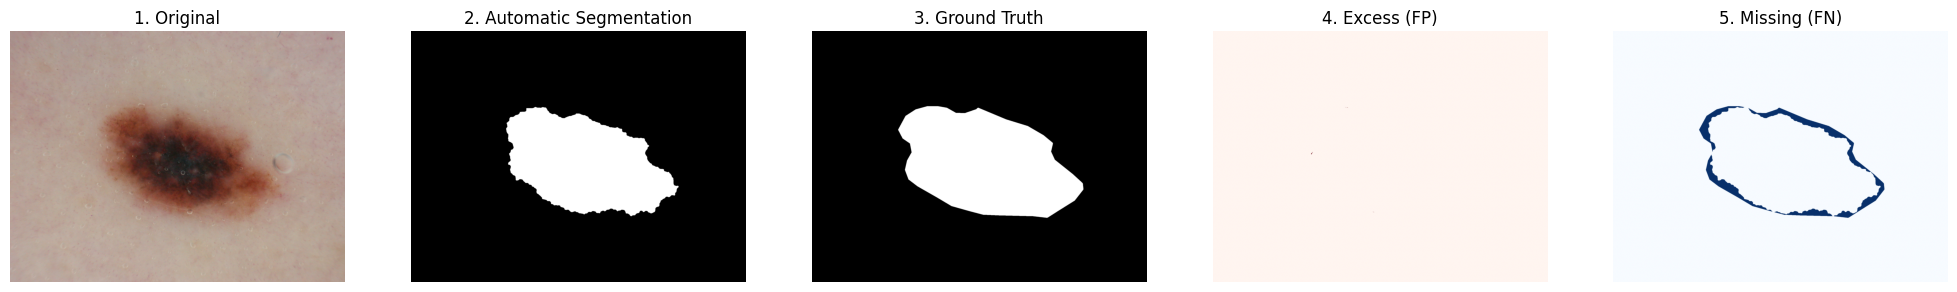

--- IMAGEN ID: ISIC_0000160 ---
IoU: 0.9149 (91.49%) | FP: 317 px | FN: 23231 px


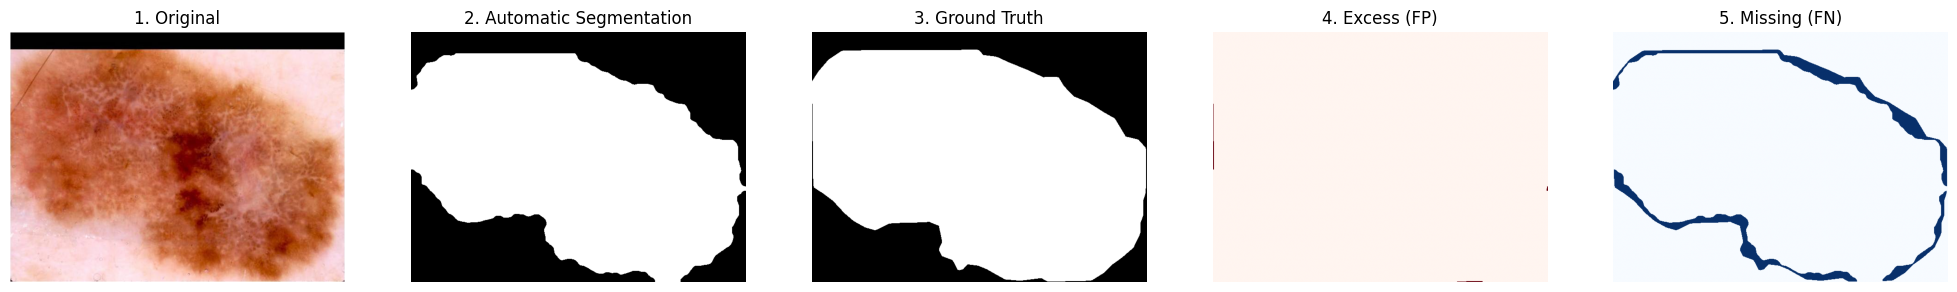

--- IMAGEN ID: ISIC_0000161 ---
IoU: 0.8187 (81.87%) | FP: 38 px | FN: 57552 px


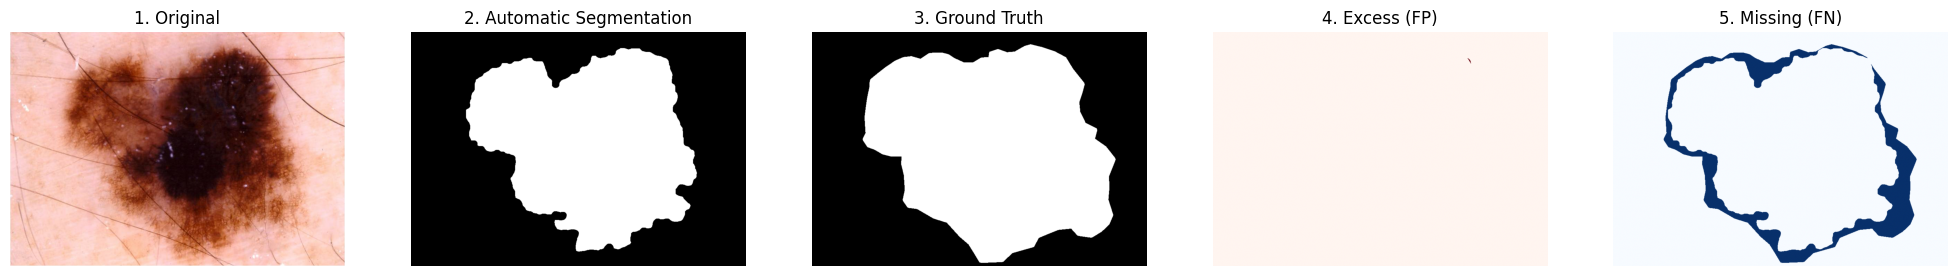

--- IMAGEN ID: ISIC_0000164 ---
IoU: 0.7786 (77.86%) | FP: 14936 px | FN: 18725 px


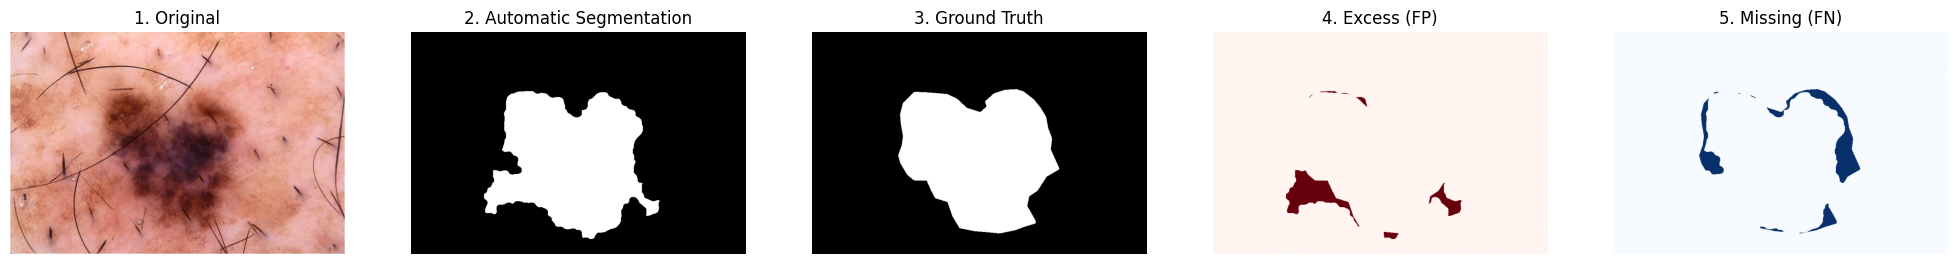

--- IMAGEN ID: ISIC_0000165 ---
IoU: 0.9128 (91.28%) | FP: 388 px | FN: 5660 px
--- IMAGEN ID: ISIC_0000169 ---
IoU: 0.7747 (77.47%) | FP: 5 px | FN: 24687 px
--- IMAGEN ID: ISIC_0000172 ---
IoU: 0.9299 (92.99%) | FP: 246 px | FN: 15717 px
--- IMAGEN ID: ISIC_0000174 ---
IoU: 0.8083 (80.83%) | FP: 9448 px | FN: 22508 px
--- IMAGEN ID: ISIC_0000482 ---
IoU: 0.9159 (91.59%) | FP: 0 px | FN: 14664 px
--- IMAGEN ID: ISIC_0000518 ---
IoU: 0.8892 (88.92%) | FP: 435 px | FN: 13278 px
--- IMAGEN ID: ISIC_0000550 ---
IoU: 0.9153 (91.53%) | FP: 47 px | FN: 18435 px
--- IMAGEN ID: ISIC_0001100 ---
IoU: 0.7702 (77.02%) | FP: 2085 px | FN: 235771 px
--- IMAGEN ID: ISIC_0009882 ---
IoU: 0.7853 (78.53%) | FP: 0 px | FN: 41865 px
--- IMAGEN ID: ISIC_0010023 ---
IoU: 0.8381 (83.81%) | FP: 20 px | FN: 37060 px
--- IMAGEN ID: ISIC_0010034 ---
IoU: 0.8197 (81.97%) | FP: 0 px | FN: 50671 px
--- IMAGEN ID: ISIC_0010175 ---
IoU: 0.7741 (77.41%) | FP: 110 px | FN: 128169 px
--- IMAGEN ID: ISIC_0010596 ---
IoU

In [5]:
# List to store all IoUs and calculate the mean at the end
lista_ious = []

# Iterate through the segmentations
for idx in range(len(mis_segmentaciones)):
    img_orig = images[idx]         # Original RGB image
    seg = mis_segmentaciones[idx]  # Automatic mask
    gt = masks_gt[idx]             # Manual mask
    
    # Create boolean binary regions
    region_manual = (gt > 0)
    region_auto = (seg > 0)
    
    # --- CALCULATIONS ---
    overlap = region_auto & region_manual
    overlap_px = np.sum(overlap)
    
    union = region_auto | region_manual
    union_px = np.sum(union)
    
    iou = overlap_px / union_px if union_px > 0 else 0
    lista_ious.append(iou)
    
    # Total areas for errors
    area_total_manual = np.sum(region_manual)
    area_total_auto = np.sum(region_auto)

    # Errors (FP and FN)
    fn_px = area_total_manual - overlap_px  # Missing (Blue)
    fp_px = area_total_auto - overlap_px    # Excess (Red)
    
    # Error images
    solo_auto = region_auto & ~region_manual   # Excess
    solo_manual = region_manual & ~region_auto # Missing
    
    # --- RESULTS ---
    print(f"--- IMAGEN ID: {ids[idx]} ---")
    print(f"IoU: {iou:.4f} ({iou*100:.2f}%) | FP: {fp_px} px | FN: {fn_px} px")

    if idx < 5:
        f, ax = plt.subplots(1, 5, figsize=(25, 5))
        ax[0].imshow(img_orig); ax[0].set_title("1. Original")
        ax[1].imshow(region_auto, cmap='gray'); ax[1].set_title("2. Automatic Segmentation")
        ax[2].imshow(region_manual, cmap='gray'); ax[2].set_title("3. Ground Truth")
        ax[3].imshow(solo_auto, cmap='Reds'); ax[3].set_title("4. Excess (FP)")
        ax[4].imshow(solo_manual, cmap='Blues'); ax[4].set_title("5. Missing (FN)")
        
        for a in ax: a.axis('off')
        plt.show()

# --- FINAL STATISTICS ---

miou_final = np.mean(lista_ious)
print("\n" + "="*45)
print(f"GLOBAL STATISTICAL RESULTS")
print(f"Mean IoU (mIoU) of Dataset: {miou_final:.4f} ({miou_final*100:.2f}%)")
print(f"Median IoU: {np.median(lista_ious):.4f}")
print(f"Minimum IoU: {np.min(lista_ious):.4f}  (ID: {ids[np.argmin(lista_ious)]})")
print(f"Maximun IoU: {np.max(lista_ious):.4f}  (ID: {ids[np.argmax(lista_ious)]})")
print("="*45)

PHASE 2

**Feature Extraction and Classification**

Calculation of the five descriptors (asymmetry, circularity, red channel mean and standard deviation, and GLCM texture) on the segmented regions, followed by the training and evaluation of the linear SVM classifier using Leave-One-Out Cross-Validation (LOOCV).

 Number of features: 5

   Asymmetry  Circularity      Mean_R      Std_R    Contrast
0   0.349597     0.758563   75.100368  45.698780  458.906259
1   0.433196     0.541668  110.551338  40.478500  207.954778
2   0.438436     0.649768  188.119170  23.986485  468.939463
3   0.353741     0.477550  109.612656  57.872824  511.038017
4   0.239468     0.375173  134.228541  43.140694  633.909876

Final LOOCV Accuracy: 90.20%


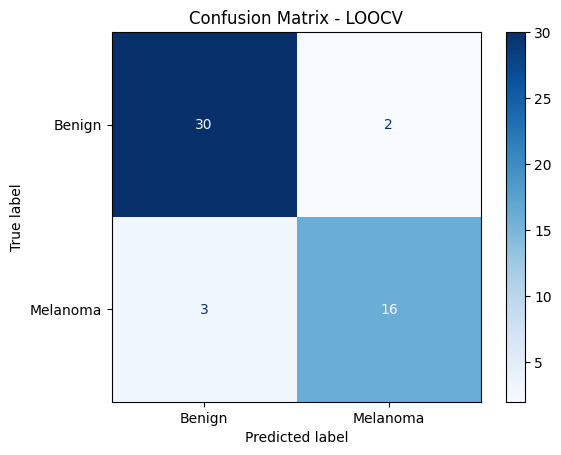


TP (correct melanomas): 16
TN (correct benigns) : 30
FP (benign -> melanoma): 2
FN (melanoma -> benign): 3

Sensitivity: 0.8421 (84.21%)
Specificity: 0.9375 (93.75%)

Misclassified images:
  ISIC_0000160: FN (melanoma -> benign)
  ISIC_0010034: FN (melanoma -> benign)
  ISIC_0010597: FN (melanoma -> benign)
  ISIC_0000327: FP (benign -> melanoma)
  ISIC_0000377: FP (benign -> melanoma)


In [6]:
# ================================================================
# MOLE CLASSIFICATION
# ================================================================

import cv2
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from skimage.feature import graycomatrix, graycoprops
import matplotlib.pyplot as plt


# ================================================================
# EXTRACTION OF 5 FEATURES (ABCDE CLINICAL RULE + TEXTURE)
# ================================================================

rows = []

for i in range(len(images)):
    img = images[i]
    mask = (mis_segmentaciones[i] > 0).astype(np.uint8)

    # CONTOURS
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        continue
    cnt = max(contours, key=cv2.contourArea)

    # Bounding box: rectangle fitted to the lesion
    bx, by, bw, bh = cv2.boundingRect(cnt)
    roi_mask = mask[by:by+bh, bx:bx+bw]   # mask cropped to the lesion

    # ============================================================
    # A — ASYMMETRY: horizontal reflection centered on the lesion itself
    # ============================================================
    roi_mask_flip = cv2.flip(roi_mask, 1)
    interseccion = np.logical_and(roi_mask, roi_mask_flip).sum()
    union = np.logical_or(roi_mask, roi_mask_flip).sum()
    asimmetry = 1 - (interseccion / union) if union > 0 else 0

    # ============================================================
    # B — CIRCULARITY: border irregularity
    # ============================================================
    area = cv2.contourArea(cnt)
    perimetro = cv2.arcLength(cnt, True)
    circularity = (4 * np.pi * area) / (perimetro**2 + 1e-7)

    # ============================================================
    # C — COLOR: mean and standard deviation of the R channel in the lesion
    # ============================================================
    pixeles_lesion = img[mask > 0]
    media_R = np.mean(pixeles_lesion[:, 0])
    std_R = np.std(pixeles_lesion[:, 0])

    # ============================================================
    # TEXTURE — GLCM Contrast (cropped to the bounding box)
    # ============================================================
    img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    roi_gray = img_gray[by:by+bh, bx:bx+bw]
    roi_gray_masked = roi_gray.copy()
    roi_gray_masked[roi_mask == 0] = 0

    glcm = graycomatrix(roi_gray_masked, distances=[5], angles=[0],
                        levels=256, symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]

    # ============================================================
    # SAVE
    # ============================================================
    rows.append({
        'Asymmetry': asimmetry,
        'Circularity': circularity,
        'Mean_R': media_R,
        'Std_R': std_R,
        'Contrast': contrast
    })

# ================================================================
# DATA MATRIX
# ================================================================
df_final = pd.DataFrame(rows)
X = df_final.values.astype(np.float32)
y = np.array(labels[:len(X)]).astype(np.int32).reshape(-1, 1)

print(f" Number of features: {X.shape[1]}")
print()
print(df_final.head())

# ================================================================
# LOOCV VALIDATION with trainAuto
# ================================================================
loo = LeaveOneOut()

y_real = []
y_pred = []

for train_index, test_index in loo.split(X):
    X_train = X[train_index]
    X_test = X[test_index]
    y_train = y[train_index]
    y_test = y[test_index]

    scaler = StandardScaler()
    X_train_std = scaler.fit_transform(X_train)
    X_test_std = scaler.transform(X_test)

    svm = cv2.ml.SVM_create()
    svm.setType(cv2.ml.SVM_C_SVC)
    svm.setKernel(cv2.ml.SVM_LINEAR) 
    svm.trainAuto(X_train_std, cv2.ml.ROW_SAMPLE, y_train)


    _, result = svm.predict(X_test_std)
    y_pred.append(int(result[0][0]))
    y_real.append(int(y_test[0][0]))

# ================================================================
# RESULTS
# ================================================================
accuracy = 100 * np.mean(np.array(y_pred) == np.array(y_real))
print(f"\nFinal LOOCV Accuracy: {accuracy:.2f}%")

cm = confusion_matrix(y_real, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Benign', 'Melanoma'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - LOOCV")
plt.show()

# ================================================================
# CLINICAL METRICS
# ================================================================
TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
sensibilidad = TP / (TP + FN) if (TP + FN) > 0 else 0
especificidad = TN / (TN + FP) if (TN + FP) > 0 else 0

print(f"\nTP (correct melanomas): {TP}")
print(f"TN (correct benigns) : {TN}")
print(f"FP (benign -> melanoma): {FP}")
print(f"FN (melanoma -> benign): {FN}")
print(f"\nSensitivity: {sensibilidad:.4f} ({sensibilidad*100:.2f}%)")
print(f"Specificity: {especificidad:.4f} ({especificidad*100:.2f}%)")

print("\nMisclassified images:")
for i, (real, pred) in enumerate(zip(y_real, y_pred)):
    if real != pred:
        tipo = "FN (melanoma -> benign)" if real == 1 else "FP (benign -> melanoma)"
        print(f"  {ids[i]}: {tipo}")

In [7]:
# ================================================================
# CORRELATION MATRIX
# ================================================================
print("\nPearson Correlation Matrix:")
matriz_corr = df_final.corr(method='pearson')
print(matriz_corr.round(2))


Pearson Correlation Matrix:
             Asymmetry  Circularity  Mean_R  Std_R  Contrast
Asymmetry         1.00        -0.44   -0.24   0.31     -0.13
Circularity      -0.44         1.00    0.19  -0.18      0.24
Mean_R           -0.24         0.19    1.00  -0.50      0.54
Std_R             0.31        -0.18   -0.50   1.00      0.02
Contrast         -0.13         0.24    0.54   0.02      1.00
